# La continuación eficiencia-uniformidad: la curva que traza y dónde la dominan iteraciones publicadas

**Pregunta:** ¿Qué curva traza una continuación sobre una sola pérdida entre eficiencia de difracción y uniformidad en la tarea de 10 x 10 trampas, es esa curva el frente de Pareto de la tarea, y dónde la dominan iteraciones de métodos publicados?

- Nivel: 4, métodos propuestos (la continuación eficiencia-uniformidad).
- Requisitos previos: `05-optimization/01-the-cost-and-its-gradient`, y `03-gerchberg-saxton/02-weights-for-uniformity` para los lazos que dan los puntos aislados.
- Tiempo de lectura: unos 30 minutos. El notebook se ejecuta en pocos minutos.

## Objetivos

Cada método de la literatura informa su calidad como un par de números, una eficiencia y una uniformidad, y elegir entre métodos suele ser elegir entre pares. Pero un par es un punto de una curva: si cambia el peso de un costo, el número de iteraciones o la eficiencia objetivo, el mismo método cae en otro lugar. Este notebook pregunta cuál es la curva. Al terminar puedes:

- ubicar cualquier holograma de un arreglo de trampas en el plano de eficiencia y uniformidad, y decir qué significa dominar a otro;
- enunciar la pérdida que minimiza el método de continuación eficiencia-uniformidad, y decir qué hacen sus dos términos y su parámetro $\lambda$;
- ejecutar los métodos de punto único del producto y la continuación que traza la curva, y leer ambos en una sola figura;
- decidir con los números si un método está sobre la curva, y cuánto le falta;
- poner a prueba la afirmación con una línea base más fuerte que la del benchmark, y decir qué sobrevive y por qué la curva no es el frente de Pareto;
- medir cuánta área agrega la curva a los puntos publicados, y cómo depende del punto de referencia del hipervolumen.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m04_gs, m05_gaa, m06_gsw, m07_phase_fixed_wgs
from pipeline.model.holo.methods.beyond import b5_pareto
from pipeline.model.holo.methods.beyond.b5_pareto import hypervolume, pareto_indices
from pipeline.model.holo.methods.optim import m09_direct_search, m11_wirtinger_adam

from pipeline.model.holo.core import traps as T
from pipeline.model.holo.core.types import Target
print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee el caso C12 de `data/examples/cases.json`, la tarea de calibración que se usa en todo el tema de optimización.

- Propietario: este repositorio; el caso es sintético y sigue la tarea de 10 x 10 de Di Leonardo, Ianni y Ruocco (2007).
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C12.

In [2]:
# caso C12: el montaje óptico y las 100 trampas de la tarea de 10 x 10
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C12"]
setup = build.setup_of(rec)
target = build.target_of(rec)
print(rec["case_id"], "|", len(target.traps), "trampas | SLM", setup.n_pix, "x", setup.n_pix, "píxeles")

C12_calibration | 100 trampas | SLM 256 x 256 píxeles


## Método

### El plano y la pérdida

Sea $I_m$ la fracción de la potencia de entrada que llega a la trampa $m$. La eficiencia es $e = \sum_m I_m$ y la uniformidad es $u = 1 - (\max I - \min I) / (\max I + \min I)$ de las intensidades divididas por sus pesos objetivo (Di Leonardo et al., 2007). Un $e$ mayor y un $u$ mayor son ambos mejores, de modo que el holograma A domina al B cuando es al menos igual de bueno en ambos y estrictamente mejor en uno. El conjunto de hologramas que nadie domina es el frente de Pareto (Boyd y Vandenberghe, 2004, sección 4.7). Un método con un parámetro libre, como el peso $f$ del costo de Polin et al. (2005) o el número de iteraciones, traza una curva en este plano; un método sin parámetro da un punto.

El método de continuación eficiencia-uniformidad traza su curva con una continuación sobre una sola pérdida. La curva es la salida de un método y no, por sí sola, un frente de Pareto: solo lo es un conjunto calculado con puntos medidos, ninguno de los cuales domina otro punto medido, y las secciones siguientes muestran puntos de la curva que dominan iteraciones de métodos publicados. Con $T_m = e_0 w_m / \sum_k w_k$ el objetivo de trampas iguales a la eficiencia $e_0$ de un holograma de partida,

$$L_\lambda(\phi) = (1 - \lambda)\,\frac{\sum_m (I_m - T_m)^2}{\sum_m T_m^2} \;-\; \lambda\,\frac{\sum_m I_m}{e_0}, \qquad \lambda \in [0, 1].$$

Con $\lambda = 0$ la pérdida pide trampas iguales a la eficiencia $e_0$ y nada más. Con $\lambda = 1$ pide solo luz, y la igualdad no se pide en absoluto. En medio cambia una por otra. El método de continuación eficiencia-uniformidad resuelve la pérdida para una malla de $\lambda$ de 0 a 1, cada vez con arranque en caliente desde la solución anterior, con gradiente conjugado, y conserva los resultados no dominados. Dividir los dos términos por $\sum T^2$ y por $e_0$ los hace adimensionales y de orden uno; esa escala es la lectura que el pipeline hace del dossier de investigación, que no declara ninguna. El hipervolumen es el área del plano, medida desde el origen, que dominan los puntos: una curva que domina más tiene mayor hipervolumen.

La primera celda ejecuta solo los dos extremos, $\lambda = 0$ y $\lambda = 1$, con 15 iteraciones de gradiente conjugado cada uno, para mostrar qué pide cada término antes de trazar la curva completa.

In [3]:
# los dos extremos de la pérdida: lambda = 0 pide trampas iguales, lambda = 1 pide solo luz
ends = b5_pareto.run(setup, target, budget=Budget(15), rng=Rng(1), n_lambda=2)
for lam, (eff, uni, sig) in zip(ends.meta["lambdas"], ends.meta["front"]):
    print(f"lambda {lam:.0f}: eficiencia {eff:.4f}  uniformidad {uni:.4f}  "
          f"desv. rel. {sig:.2f} %")
    print(f"             trampa más tenue sobre la más brillante: {uni / (2 - uni):.4f}")
print(f"eficiencia del inicio (WGS de fase fija): {ends.meta['e0']:.4f}")

lambda 0: eficiencia 0.7930  uniformidad 1.0000  desv. rel. 0.00 %
             trampa más tenue sobre la más brillante: 1.0000
lambda 1: eficiencia 0.8293  uniformidad 0.0062  desv. rel. 82.10 %
             trampa más tenue sobre la más brillante: 0.0031
eficiencia del inicio (WGS de fase fija): 0.7930


Los dos extremos se comportan como dice la pérdida. Con $\lambda = 0$ el arreglo es perfectamente igual, con una desviación estándar relativa de 0,00 por ciento y una uniformidad de 1,0000, con una eficiencia de 0,7930, que es exactamente el $e_0$ del inicio. Con $\lambda = 1$ el optimizador sube la eficiencia a 0,8293 y renuncia a la igualdad: la desviación estándar relativa es 82,10 por ciento y la uniformidad 0,0062, de modo que la trampa más tenue está casi oscura: con la uniformidad de la sección Método, 0,0062 significa que la trampa más tenue tiene 0,0031 de la intensidad de la más brillante (impreso arriba), y la desviación estándar relativa de 82,10 por ciento dice que la dispersión no es obra de una sola trampa. Los dos extremos están lejos en uniformidad, de 1,0000 a 0,0062, y cerca en eficiencia, de 0,7930 a 0,8293, una ganancia de 4,6 por ciento de la luz. Este es el primer hecho sobre la curva, y las celdas siguientes lo miden con la curva completa: el compromiso en esta tarea es empinado, y casi todo se paga en uniformidad.

## Comparación

Los métodos de punto único son aquello frente a lo que se mide el método de continuación eficiencia-uniformidad. Cada uno se ejecuta aquí como la implementación propia del pipeline, con el presupuesto de 30 iteraciones del benchmark y la misma semilla: Gerchberg-Saxton simple, el lazo aditivo adaptativo generalizado y el lazo ponderado de Di Leonardo et al. (2007), y el GS ponderado de fase fija, el método para arreglos grandes de Kim et al. (2019). La primera celda ejecuta esos cuatro.

In [4]:
# cuatro métodos de proyección con el presupuesto de 30 iteraciones del benchmark, semilla 1
h04 = m04_gs.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
h05 = m05_gaa.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
h06 = m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
h07 = m07_phase_fixed_wgs.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
for name, h in (("Gerchberg-Saxton", h04), ("Aditivo adaptativo generalizado", h05), ("GS ponderado", h06),
    ("GS ponderado con fase fija", h07)):
    print(f"{name:32s} eficiencia {h['efficiency']:.4f}  uniformidad {h['uniformity']:.4f}")

Gerchberg-Saxton                 eficiencia 0.8105  uniformidad 0.6172
Aditivo adaptativo generalizado  eficiencia 0.8089  uniformidad 0.7053
GS ponderado                     eficiencia 0.8023  uniformidad 0.9665
GS ponderado con fase fija       eficiencia 0.7930  uniformidad 0.9997


Dos puntos más vienen de la familia de optimización. La búsqueda directa cambia un píxel a la vez para bajar el costo de Polin et al. (2005), $C = -\langle I \rangle + f \sigma$, con $f = 0{,}5$; paga un precio en eficiencia por la uniformidad, por construcción. Wirtinger-Adam, del notebook anterior, minimiza la pérdida cuadrática con pasos de gradiente.

In [5]:
# búsqueda directa (2 barridos de los píxeles) y Wirtinger-Adam (30 iteraciones), misma tarea y semilla
h09 = m09_direct_search.run(setup, target, budget=Budget(2), rng=Rng(1)).history[-1]
h11 = m11_wirtinger_adam.run(setup, target, budget=Budget(30), rng=Rng(1)).history[-1]
for name, h in (("Búsqueda directa", h09), ("Gradiente de Wirtinger con Adam", h11)):
    print(f"{name:32s} eficiencia {h['efficiency']:.4f}  uniformidad {h['uniformity']:.4f}")

Búsqueda directa                 eficiencia 0.6584  uniformidad 0.9994
Gradiente de Wirtinger con Adam  eficiencia 0.7629  uniformidad 0.9327


La figura ubica los seis resultados en el plano de eficiencia y uniformidad.

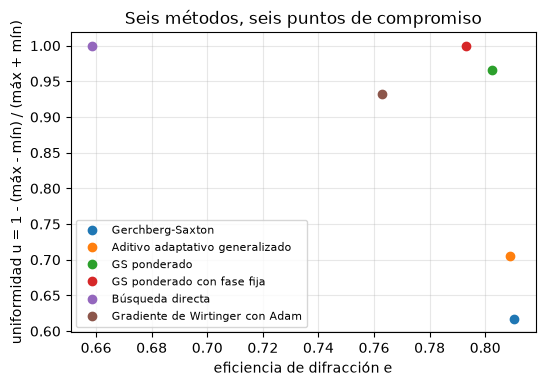

In [6]:
# los seis resultados puntuales en el plano de eficiencia y uniformidad
base = {"Gerchberg-Saxton": h04, "Aditivo adaptativo generalizado": h05, "GS ponderado": h06,
    "GS ponderado con fase fija": h07, "Búsqueda directa": h09, "Gradiente de Wirtinger con Adam": h11}
fig, ax = plt.subplots(figsize=(6.0, 3.9))
for name, h in base.items():
    ax.plot(h["efficiency"], h["uniformity"], "o", label=name)
ax.set_xlabel("eficiencia de difracción e")
ax.set_ylabel("uniformidad u = 1 - (máx - mín) / (máx + mín)")
ax.set_title("Seis métodos, seis puntos de compromiso")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

Los seis puntos caen en tres grupos. Gerchberg-Saxton y el aditivo adaptativo generalizado tienen la mayor eficiencia, 0,8105 y 0,8089, y la menor uniformidad, 0,6172 y 0,7053: son los lazos de proyección que ponen luz en las trampas y dejan las trampas desiguales. El GS ponderado tiene una eficiencia de 0,8023 y una uniformidad de 0,9665, y el GS ponderado con fase fija queda en 0,7930 y 0,9997 tras las mismas 30 iteraciones; el gradiente de Wirtinger con Adam está cerca de ellos en 0,7629 y 0,9327. La búsqueda directa también está en el extremo uniforme, con una uniformidad de 0,9994 y una eficiencia de solo 0,6584, que es el precio de su peso $f = 0,5$. La figura muestra seis puntos, y nada en ella dice si un punto podría moverse hacia arriba o a la derecha con el mismo método. No puede mostrar la curva que trazaría cada parámetro, y esa es la brecha que aborda el método de continuación eficiencia-uniformidad: la literatura compara estos puntos, ninguna de las fuentes citadas aquí informa la curva completa en una tarea, y este notebook no buscó una que lo haga.

### Búsqueda directa, el único punto que no es un lazo de proyección

La búsqueda directa (Polin et al. 2005) no lleva la luz de ida y vuelta: cambia un píxel a la vez. Con $I_m$ las intensidades de las trampas e $I^D_m = w_m/\bar w$ las intensidades de diseño, baja el costo

$$C=-\langle I\rangle+f\,\sigma,\qquad \sigma=\sqrt{\frac1M\sum_m\big(I_m-\gamma I^D_m\big)^2},\qquad \gamma=\frac{\sum_m I_m I^D_m}{\sum_m \big(I^D_m\big)^2},$$

donde $\langle I\rangle$ es la intensidad media de las trampas (la eficiencia dividida por las $M$ trampas), $\sigma$ la dispersión de las trampas en torno al múltiplo $\gamma I^D$ del diseño que mejor ajusta, y $f$ el peso de la uniformidad frente a la luz. Un barrido visita una vez los $N^2$ píxeles en orden aleatorio; en cada píxel prueba $P = 8$ fases $2\pi k/P$ y conserva la mejor solo si baja $C$, de modo que $C$ nunca sube. Cambiar el píxel $j$ de la fase $\phi$ a $\phi'$ cambia cada campo de trampa en $V_m \leftarrow V_m + (A_j/N^2)\,(e^{i\phi'} - e^{i\phi})\,e^{-i\Delta_j^m}$, con $A_j$ la amplitud del haz en el píxel y $e^{-i\Delta_j^m}$ el factor de propagación del píxel a la trampa $m$: una actualización de orden $M$ y no una transformada nueva, que es lo que hace asequibles las $P N^2$ pruebas de un barrido. Tres límites se siguen de la construcción: las visitas son secuenciales, un descenso píxel a píxel no puede salir de un mínimo local, y un barrido cuesta $P N^2$ pruebas de orden $M$ por bueno que ya sea el holograma. La celda ejecuta la búsqueda directa durante dos barridos con $f = 0$, $0,5$ y $2$ e imprime la eficiencia y la uniformidad tras cada barrido, las pruebas hasta ahí y el número de píxeles cambiados.

In [7]:
# búsqueda directa: el costo de Polin et al. con tres pesos f, dos barridos cada uno, el estado tras cada barrido
direct = {}
for f in (0.0, 0.5, 2.0):
    direct[f] = m09_direct_search.run(setup, target, budget=Budget(2), rng=Rng(1), f=f)
    for h in direct[f].history:
        print(f"f = {f:.1f}, barrido {h['iteration']}: eficiencia {h['efficiency']:.4f}  "
              f"uniformidad {h['uniformity']:.4f}  pruebas hasta ahora {h['trials']}")
    changed, visits = direct[f].meta["accepted"], 2 * setup.n_pix**2
    print(f"           píxeles cambiados en los dos barridos: {changed} de {visits} visitas")


f = 0.0, barrido 1: eficiencia 0.7584  uniformidad 0.0086  pruebas hasta ahora 524288
f = 0.0, barrido 2: eficiencia 0.7727  uniformidad 0.0011  pruebas hasta ahora 1048576
           píxeles cambiados en los dos barridos: 19635 de 131072 visitas
f = 0.5, barrido 1: eficiencia 0.6582  uniformidad 0.9996  pruebas hasta ahora 524288
f = 0.5, barrido 2: eficiencia 0.6584  uniformidad 0.9994  pruebas hasta ahora 1048576
           píxeles cambiados en los dos barridos: 17036 de 131072 visitas
f = 2.0, barrido 1: eficiencia 0.5366  uniformidad 0.9997  pruebas hasta ahora 524288
f = 2.0, barrido 2: eficiencia 0.5366  uniformidad 0.9996  pruebas hasta ahora 1048576
           píxeles cambiados en los dos barridos: 10130 de 131072 visitas


La figura pone los tres pesos en el plano de eficiencia y uniformidad, junto al lazo ponderado y al GS ponderado con fase fija.

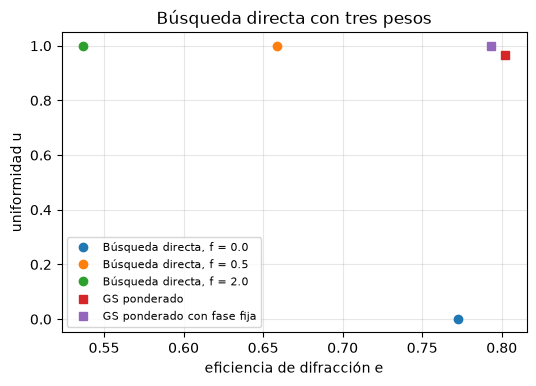

In [8]:
# los tres pesos de búsqueda directa tras dos barridos, con el GS ponderado y el GS ponderado con fase fija de la figura
# de seis puntos
fig, ax = plt.subplots(figsize=(6.0, 3.9))
for f, res in direct.items():
    ax.plot(res.history[-1]["efficiency"], res.history[-1]["uniformity"], "o", label=f"Búsqueda directa, f = {f}")
for name in ("GS ponderado", "GS ponderado con fase fija"):
    ax.plot(base[name]["efficiency"], base[name]["uniformity"], "s", label=name)
ax.set_xlabel("eficiencia de difracción e")
ax.set_ylabel("uniformidad u")
ax.set_title("Búsqueda directa con tres pesos")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()


El peso $f$ fija dónde cae la búsqueda directa, y un segundo barrido casi no agrega nada. Con $f = 0$ el costo pide solo luz: la eficiencia llega a 0,7727 y la uniformidad se desploma a 0,0011. Con $f = 0,5$, el peso de la figura de seis puntos, un barrido da una eficiencia de 0,6582 y una uniformidad de 0,9996 y el segundo las mueve a 0,6584 y 0,9994; con $f = 2$ la eficiencia es 0,5366 tras ambos barridos. Cada barrido son 524288 pruebas, 8 fases en cada uno de los 65536 píxeles, y los píxeles cambiados en los dos barridos son 19635, 17036 y 10130 de 131072 visitas, de modo que la mayoría de las visitas no cambia nada. Con $f = 0,5$ y $2$ esto es la construcción mostrando su límite: tras un barrido un descenso píxel a píxel no tiene movimiento que baje el costo, y el compromiso en que se asienta, 0,6584 de la luz frente a 0,7930 del GS ponderado con fase fija con una uniformidad de cerca de 1, lo fija el peso y no lo encuentra la búsqueda. La figura pone los tres pesos curva al GS ponderado y el GS ponderado con fase fija: la búsqueda directa con $f = 0,5$ y $2$ queda en el extremo uniforme con menos luz que el GS ponderado con fase fija, y con $f = 0$ queda en el otro extremo con más luz que el GS ponderado con fase fija y casi nada de uniformidad. No dice que otro inicio u otro orden de las visitas no lo haría mejor; el notebook corrió un inicio, la superposición del caso, y un orden aleatorio por peso.

## Evidencia

### La curva por continuación sobre una sola pérdida

La afirmación del método de continuación eficiencia-uniformidad es que una continuación sobre una sola pérdida devuelve la curva completa al precio de unas pocas corridas de gradiente conjugado, y que ningún método de punto único está sobre él. La celda siguiente la ejecuta con 20 valores de $\lambda$ y 15 iteraciones de gradiente conjugado para cada uno, cada una con su búsqueda lineal, tras un inicio del GS ponderado con fase fija de 30 iteraciones, e imprime siete de los 20 puntos; cada método de punto único de abajo recibe 30 iteraciones, de modo que la curva cuesta mucho más que cualquiera de ellos.

In [9]:
# la curva: 20 valores de lambda, 15 iteraciones de gradiente conjugado cada uno, cada uno desde su vecino
res_b5 = b5_pareto.run(setup, target, budget=Budget(15), rng=Rng(1))
front = res_b5.meta["front"]
for k in (0, 3, 6, 9, 12, 15, 19):
    print(f"lambda {res_b5.meta['lambdas'][k]:.2f}: eficiencia {front[k, 0]:.4f}  "
          f"uniformidad {front[k, 1]:.4f}  desv. rel. {front[k, 2]:.2f} %")
print(f"puntos que quedan como no dominados: {len(res_b5.meta['pareto'])} de {len(front)}")

lambda 0.00: eficiencia 0.7930  uniformidad 1.0000  desv. rel. 0.00 %
lambda 0.16: eficiencia 0.8034  uniformidad 0.9769  desv. rel. 1.02 %
lambda 0.32: eficiencia 0.8087  uniformidad 0.9425  desv. rel. 2.23 %
lambda 0.47: eficiencia 0.8119  uniformidad 0.9077  desv. rel. 3.99 %
lambda 0.63: eficiencia 0.8146  uniformidad 0.8449  desv. rel. 6.99 %
lambda 0.79: eficiencia 0.8183  uniformidad 0.7083  desv. rel. 12.75 %
lambda 1.00: eficiencia 0.8334  uniformidad 0.0074  desv. rel. 72.89 %
puntos que quedan como no dominados: 20 de 20


La curva no es una nube: los 20 puntos son no dominados entre sí. Su eficiencia va de 0,7930 a 0,8334 mientras su uniformidad va de 1,0000 a 0,0074, y la mayor parte de la pérdida de uniformidad llega al final de la curva, entre $\lambda = 0,79$ y $\lambda = 1$. Ahora la afirmación: para cada punto único, la celda cuenta los puntos de la curva que lo dominan, y lee la eficiencia que ofrece la curva con la misma uniformidad. La celda también compara el hipervolumen de la curva con el de los puntos únicos, que es el criterio de aceptación del método de continuación eficiencia-uniformidad en la escalera de métodos.

In [10]:
# para cada punto aislado: los puntos de la curva que lo dominan y la eficiencia de la curva con su uniformidad
by_uniformity = np.argsort(front[:, 1])
for name, h in base.items():
    e, u = h["efficiency"], h["uniformity"]
    better = (front[:, 0] >= e) & (front[:, 1] >= u) & ((front[:, 0] > e) | (front[:, 1] > u))
    offered = np.interp(u, front[by_uniformity, 1], front[by_uniformity, 0])
    print(f"{name:32s} dominado por {int(better.sum()):2d} puntos de la curva | "
          f"eficiencia de la curva con su uniformidad {offered:.4f} "
          f"frente a {e:.4f}")
pairs = {k: [h["efficiency"], h["uniformity"]] for k, h in base.items()}
hv_six = hypervolume(np.array(list(pairs.values())))
hv_four = hypervolume(np.array([pairs[k] for k in ("Gerchberg-Saxton", "Aditivo adaptativo generalizado",
    "Búsqueda directa", "GS ponderado")]))
print(f"hipervolumen de la curva: {res_b5.meta['hypervolume']:.4f}")
print(f"hipervolumen de los seis puntos: {hv_six:.4f} | de los cuatro del criterio: {hv_four:.4f}")

Gerchberg-Saxton                 dominado por  9 puntos de la curva | eficiencia de la curva con su uniformidad 0.8205 frente a 0.8105
Aditivo adaptativo generalizado  dominado por  9 puntos de la curva | eficiencia de la curva con su uniformidad 0.8184 frente a 0.8089
GS ponderado                     dominado por  2 puntos de la curva | eficiencia de la curva con su uniformidad 0.8056 frente a 0.8023
GS ponderado con fase fija       dominado por  0 puntos de la curva | eficiencia de la curva con su uniformidad 0.7931 frente a 0.7930
Búsqueda directa                 dominado por  1 puntos de la curva | eficiencia de la curva con su uniformidad 0.7932 frente a 0.6584
Gradiente de Wirtinger con Adam  dominado por  7 puntos de la curva | eficiencia de la curva con su uniformidad 0.8097 frente a 0.7629
hipervolumen de la curva: 0.8198
hipervolumen de los seis puntos: 0.8074 | de los cuatro del criterio: 0.8028


La figura dibuja la curva y los seis puntos aislados juntos.

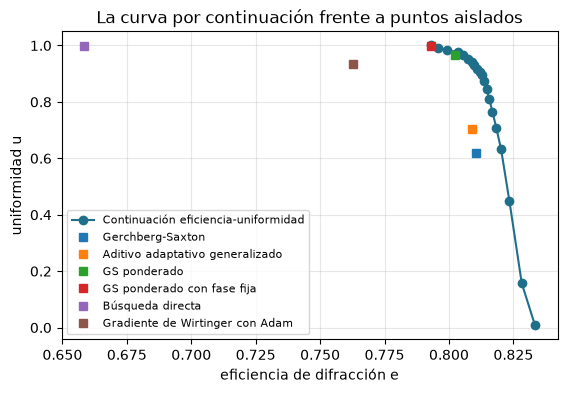

In [11]:
# la curva y los seis puntos en un mismo plano
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(front[:, 0], front[:, 1], "o-", color="#1f6f8b", label="Continuación eficiencia-uniformidad")
for name, h in base.items():
    ax.plot(h["efficiency"], h["uniformity"], "s", label=name)
ax.set_xlabel("eficiencia de difracción e")
ax.set_ylabel("uniformidad u")
ax.set_title("La curva por continuación frente a puntos aislados")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

Cinco de los seis puntos únicos están dominados, por entre 1 y 9 puntos de la curva; el GS ponderado con fase fija no lo está, y la razón es el inicio: la continuación parte del propio holograma del GS ponderado con fase fija, así que el extremo uniforme de la curva es el GS ponderado con fase fija refinado, y con la uniformidad del GS ponderado con fase fija la curva ofrece 0,7931 frente a 0,7930, una diferencia bajo la cuarta cifra. Los otros márgenes difieren mucho. Con la uniformidad de la búsqueda directa la curva ofrece una eficiencia de 0,7932 frente a 0,6584, una ganancia de 0,1348 de la luz; para el gradiente de Wirtinger con Adam ofrece 0,8097 frente a 0,7629. Para los lazos de proyección Gerchberg-Saxton y el aditivo adaptativo generalizado el margen es de cerca de 0,01, y para el GS ponderado es 0,8056 frente a 0,8023. El hipervolumen de la curva es 0,8198 frente a 0,8074 de los seis puntos y 0,8028 de los cuatro del criterio, de modo que el criterio de aceptación del método de continuación eficiencia-uniformidad se cumple. Lo que la figura no dice es cuán robustos son estos márgenes: vienen de una semilla y un presupuesto. El hipervolumen es además una herramienta tosca aquí, porque el origen está lejos y cada punto ya cubre cerca de 0,8 del cuadrado unitario.

La curva de arriba sale de una semilla. La celda siguiente repite toda la prueba con las semillas 2 y 3: los seis puntos únicos, la curva de 20 puntos desde un inicio de 30 iteraciones, el número de puntos únicos bajo la curva y los hipervolúmenes del criterio.

In [12]:
# la prueba de la curva con dos semillas más: los seis puntos, la curva de 20 puntos, los dominados, los hipervolúmenes
runners = {"Gerchberg-Saxton": (m04_gs.run, 30), "Aditivo adaptativo generalizado": (m05_gaa.run, 30),
    "GS ponderado": (m06_gsw.run, 30),
           "GS ponderado con fase fija": (m07_phase_fixed_wgs.run, 30), "Búsqueda directa": (m09_direct_search.run, 2),
           "Gradiente de Wirtinger con Adam": (m11_wirtinger_adam.run, 30)}
for seed in (2, 3):
    points = {name: run(setup, target, budget=Budget(b), rng=Rng(seed)).history[-1]
              for name, (run, b) in runners.items()}
    seeded = b5_pareto.run(setup, target, budget=Budget(15), rng=Rng(seed))
    fr = seeded.meta["front"]
    below = []
    for name, h in points.items():
        e, u = h["efficiency"], h["uniformity"]
        if np.any((fr[:, 0] >= e) & (fr[:, 1] >= u) & ((fr[:, 0] > e) | (fr[:, 1] > u))):
            below.append(name)
    xy = {name: [h["efficiency"], h["uniformity"]] for name, h in points.items()}
    hv_four = hypervolume(np.array([xy[k] for k in ("Gerchberg-Saxton", "Aditivo adaptativo generalizado",
        "Búsqueda directa", "GS ponderado")]))
    print(f"semilla {seed}: eficiencia de la curva {fr[0, 0]:.4f} a {fr[-1, 0]:.4f}, "
          f"uniformidad {fr[0, 1]:.4f} a {fr[-1, 1]:.4f}")
    print(f"   puntos únicos bajo la curva: {len(below)} de 6 ({', '.join(below)})")
    hv_six = hypervolume(np.array(list(xy.values())))
    print(f"   hipervolumen: curva {seeded.meta['hypervolume']:.4f}, seis puntos {hv_six:.4f}, "
          f"los cuatro del criterio {hv_four:.4f}")


semilla 2: eficiencia de la curva 0.7908 a 0.8352, uniformidad 1.0000 a 0.0150
   puntos únicos bajo la curva: 4 de 6 (Gerchberg-Saxton, GS ponderado con fase fija, Búsqueda directa, Gradiente de Wirtinger con Adam)
   hipervolumen: curva 0.8218, seis puntos 0.8113, los cuatro del criterio 0.8113
semilla 3: eficiencia de la curva 0.7931 a 0.8356, uniformidad 1.0000 a 0.0053
   puntos únicos bajo la curva: 6 de 6 (Gerchberg-Saxton, Aditivo adaptativo generalizado, GS ponderado, GS ponderado con fase fija, Búsqueda directa, Gradiente de Wirtinger con Adam)
   hipervolumen: curva 0.8216, seis puntos 0.8115, los cuatro del criterio 0.8075


En la semilla 2 cuatro de los seis puntos únicos quedan bajo la curva (el aditivo adaptativo generalizado y el GS ponderado no) y en la semilla 3 lo hacen los seis, frente a cinco de seis en la semilla 1: el conteo no es una constante de la tarea, y cuáles lazos quedan sobre la curva cambia con la semilla. El criterio del hipervolumen se cumple en las tres semillas: la curva tiene 0,8198, 0,8218 y 0,8216 (semillas 1, 2 y 3) frente a 0,8074, 0,8113 y 0,8115 de los seis puntos y 0,8028, 0,8113 y 0,8075 de los cuatro del criterio. La curva cubre un rango de eficiencia de 0,7908 a 0,8352 en la semilla 2 y de 0,7931 a 0,8356 en la semilla 3, cerca del 0,7930 a 0,8334 de la semilla 1, y su uniformidad termina en 0,0150 y 0,0053 frente a 0,0074. Tres semillas siguen siendo pocas: muestran cuánto se mueve el conteo y no son un intervalo para él.

### Dónde falla la curva: una línea base más fuerte que la del benchmark

El benchmark fija 30 iteraciones para cada método, y la curva de arriba partió de un holograma de 30 iteraciones. Una prueba justa de una afirmación sobre una curva debe darle más esfuerzo a la línea base, ya que un método de punto único es una sola corrida. La línea base más fuerte para el extremo uniforme es el lazo ponderado, cuya uniformidad sigue mejorando con las iteraciones. La celda lo ejecuta 100 iteraciones y cuenta los puntos de la curva que domina.

In [13]:
# la línea base puntual más fuerte: GS ponderado con 100 iteraciones en lugar de 30
res_long = m06_gsw.run(setup, target, budget=Budget(100), rng=Rng(1))
e_long, u_long = res_long.history[-1]["efficiency"], res_long.history[-1]["uniformity"]
beaten = (e_long >= front[:, 0]) & (u_long >= front[:, 1]) & ((e_long > front[:, 0]) | (u_long > front[:, 1]))
print(f"GS ponderado, 100 iteraciones: eficiencia {e_long:.4f}  uniformidad {u_long:.4f}")
print(f"puntos de la curva que domina: {int(beaten.sum())} de {len(front)}")
published = np.vstack([[[h["efficiency"], h["uniformity"]] for h in base.values()], [[e_long, u_long]]])
below_any = [bool(np.any(np.all(published >= p, axis=1) & np.any(published > p, axis=1))) for p in front[:, :2]]
print(f"puntos de la curva dominados por al menos uno de los siete puntos publicados: {sum(below_any)} de {len(front)}")

GS ponderado, 100 iteraciones: eficiencia 0.8075  uniformidad 0.9887
puntos de la curva que domina: 4 de 20
puntos de la curva dominados por al menos uno de los siete puntos publicados: 4 de 20


La afirmación falla en parte. Un holograma de GS ponderado de 100 iteraciones, con una eficiencia de 0,8075 y una uniformidad de 0,9887, domina 4 de los 20 puntos de la curva: la curva subestima lo alcanzable cerca del extremo uniforme, porque su continuación partió de un inicio de 30 iteraciones con una eficiencia de solo 0,7930 y gastó 15 iteraciones por valor. La curva no es una propiedad de la tarea sola sino de la tarea, del holograma de inicio y del presupuesto. El método de continuación eficiencia-uniformidad acepta una fase de inicio, así que la reparación es empezar la continuación desde el mejor holograma. La celda lo hace con 8 valores de $\lambda$ y 30 iteraciones cada uno, e imprime los dos extremos de la nueva curva.

In [14]:
# la misma continuación iniciada desde ese holograma mejor: 8 valores de lambda, 30 iteraciones cada uno
res_warm = b5_pareto.run(setup, target, budget=Budget(30), rng=Rng(1), n_lambda=8, init=res_long.phi)
front_warm = res_warm.meta["front"]
print(f"extremo uniforme del curva nueva: e {front_warm[0, 0]:.4f}  u {front_warm[0, 1]:.4f}")
print(f"extremo de eficiencia: e {front_warm[-1, 0]:.4f}  u {front_warm[-1, 1]:.4f}")
print(f"hipervolumen, curva nueva: {res_warm.meta['hypervolume']:.4f} | "
      f"primer frente: {res_b5.meta['hypervolume']:.4f}")

extremo uniforme del curva nueva: e 0.8075  u 1.0000
extremo de eficiencia: e 0.8370  u 0.0101
hipervolumen, curva nueva: 0.8216 | primer frente: 0.8198


La figura dibuja ambas curvas y el punto de 100 iteraciones.

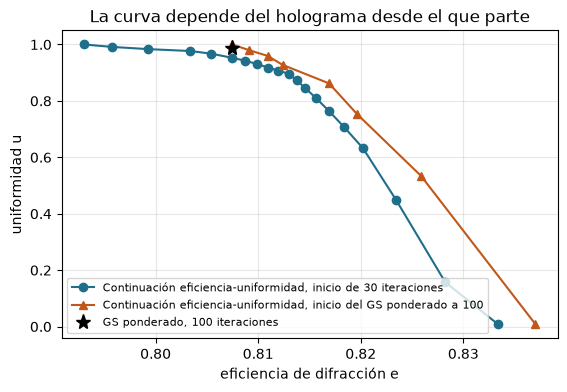

In [15]:
# ambas curvas y el punto del GS ponderado largo
fig, ax = plt.subplots(figsize=(6.4, 4.0))
ax.plot(front[:, 0], front[:, 1], "o-", color="#1f6f8b",
    label="Continuación eficiencia-uniformidad, inicio de 30 iteraciones")
ax.plot(front_warm[:, 0], front_warm[:, 1], "^-", color="#c2571a",
    label="Continuación eficiencia-uniformidad, inicio del GS ponderado a 100")
ax.plot(e_long, u_long, "k*", markersize=11, label="GS ponderado, 100 iteraciones")
ax.set_xlabel("eficiencia de difracción e")
ax.set_ylabel("uniformidad u")
ax.set_title("La curva depende del holograma desde el que parte")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

La nueva curva empieza donde termina la línea base más fuerte: su extremo uniforme está en una eficiencia de 0,8075 y una uniformidad de 1,0000, que coincide con la eficiencia del GS ponderado a 100 iteraciones hasta la cuarta cifra y elimina el 0,0113 de falta de uniformidad que quedaba, y su extremo de eficiencia llega a 0,8370 frente a 0,8334 de la primera curva. Su hipervolumen, 0,8216, queda sobre el 0,8198 de la primera curva. La celda siguiente pregunta cómo se sitúan las dos curvas uno curva al otro.

In [16]:
# dónde la curva de 8 puntos deja sin cubrir al de 20, y el hipervolumen de las dos curvas juntos
# dominancia solo en eficiencia y uniformidad: la desv. est. relativa de la tercera columna es mejor cuanto menor
covered = [bool(np.any(np.all(front_warm[:, :2] >= p, axis=1) & np.any(front_warm[:, :2] > p, axis=1)))
           for p in front[:, :2]]
open_points = front[~np.array(covered)]
print(f"puntos de la primera curva que ningún punto del nuevo domina: {len(open_points)} de {len(front)}")
print(f"sus eficiencias: {open_points[:, 0].min():.4f} a {open_points[:, 0].max():.4f}")
union = np.vstack([front, front_warm])[:, :2]
print(f"hipervolumen de la unión de ambas curvas: {hypervolume(union[pareto_indices(union)]):.4f}")


puntos de la primera curva que ningún punto del nuevo domina: 5 de 20
sus eficiencias: 0.7930 a 0.8282
hipervolumen de la unión de ambas curvas: 0.8220


Las dos curvas se intercalan: la nueva curva domina 15 de los 20 puntos de la primera, y 5, con eficiencias de 0,7930 a 0,8282, no están dominados por ningún punto de la nueva, porque sus 8 valores de $\lambda$ dejan huecos entre sus puntos. La unión de ambas queda sobre cualquiera de las dos, 0,8220, así que ninguna curva es el compromiso completo. La figura no muestra que una curva sea el verdadero frente de Pareto de la tarea: solo muestra que la primera no lo era. Un tercer inicio, o más iteraciones por valor, probablemente la movería de nuevo, y este notebook no tiene una estimación del límite. La afirmación segura es una dependencia: la curva que devuelve el método de continuación eficiencia-uniformidad es tan buena como el holograma desde el que parte y la densidad de sus $\lambda$, y no mejor.

El hipervolumen medido desde el origen lo domina el extremo uniforme: cada punto ya cubre cerca de 0,8 del cuadrado unitario, y el área agregada de la curva está en eficiencias sobre la del GS ponderado con fase fija, donde la uniformidad cae hacia cero, una región en la que ningún experimento operaría. Un punto de referencia dentro del plano descuenta esa región. La celda siguiente compara la curva con la unión de cinco puntos publicados (Gerchberg-Saxton, aditivo adaptativo generalizado, GS ponderado, GS ponderado con fase fija y búsqueda directa, los seis puntos de la primera figura sin el gradiente de Wirtinger con Adam) con tres referencias del hipervolumen: el origen, un piso de eficiencia de 0,5 y un piso de uniformidad de 0,9, e imprime el área que la curva agrega con cada una.

In [17]:
# el área que la curva agrega a los cinco puntos publicados, con tres referencias del hipervolumen
five = np.array([[h["efficiency"], h["uniformity"]] for h in (h04, h05, h06, h07, h09)])
references = (
    ("origen (0, 0)", (0.0, 0.0)),
    ("piso de eficiencia (0,5; 0)", (0.5, 0.0)),
    ("piso de uniformidad (0; 0,9)", (0.0, 0.9)),
)
for label, ref in references:
    area_curve = hypervolume(front[:, :2], ref)
    area_five = hypervolume(five, ref)
    print(f"referencia {label}: curva {area_curve:.4f}, cinco puntos publicados {area_five:.4f}, "
          f"ganancia {area_curve - area_five:+.4f}")

referencia origen (0, 0): curva 0.8198, cinco puntos publicados 0.8074, ganancia +0.0124
referencia piso de eficiencia (0,5; 0): curva 0.3198, cinco puntos publicados 0.3076, ganancia +0.0123
referencia piso de uniformidad (0; 0,9): curva 0.0805, cinco puntos publicados 0.0797, ganancia +0.0008


Desde el origen la curva agrega +0,0124 de área a los cinco puntos publicados (0,8198 frente a 0,8074), y con un piso de eficiencia de 0,5 agrega +0,0123: un piso de eficiencia descuenta solo el eje de la eficiencia, y el área agregada no vive ahí. Con un piso de uniformidad de 0,9 la curva agrega +0,0008 (0,0805 frente a 0,0797), cerca de 6 por ciento de la ganancia en el origen. La razón es la forma de la curva en la salida de la sección Evidencia: su ganancia de eficiencia, de 0,7930 a 0,8334, se compra con uniformidades que cruzan 0,9 entre $\lambda = 0,47$ (0,9077) y $\lambda = 0,63$ (0,8449), de modo que una referencia que pide una uniformidad sobre 0,9 conserva solo la parte de la curva hasta una eficiencia de cerca de 0,81, donde ya hay puntos publicados. La lectura es de una semilla y una red; el manuscrito del método, con ocho semillas, halla que el margen en (0; 0,9) es 12,4 por ciento del que hay en el origen (`hvRefFiveUNineShare` en sus datos), del mismo orden. La medida que usa el benchmark, el área desde el origen, favorece por tanto a la continuación: quien necesite una uniformidad sobre 0,9 debe leer el área en (0; 0,9), donde la ganancia es pequeña.

### Úsalo con tus propios datos

La curva es una propiedad de una tarea, de modo que para obtener la curva de tu propio arreglo le das al método de continuación eficiencia-uniformidad el arreglo, un holograma inicial y un presupuesto. La pérdida sobre la que continúa, escrita en el registro del método del producto, es

$$L_\lambda(\phi) = (1-\lambda)\,\frac{\sum_m (I_m - T_m)^2}{\sum_m T_m^2} \;-\; \lambda\,\frac{\sum_m I_m}{e_0}, \qquad T_m = e_0\,\frac{w_m}{\sum_k w_k},$$

donde $I_m$ es la intensidad en la trampa $m$, $w_m$ su peso y $e_0$ la eficiencia del holograma inicial, de modo que $T_m$ es el arreglo igual por peso que lleva la luz que el inicio ya lleva. Los dos términos se dividen por $\sum_m T_m^2$ y por $e_0$ para que ambos sean de orden uno y $\lambda$ los pese por igual. En $\lambda = 0$ la pérdida pide el arreglo igual y en $\lambda = 1$ solo luz. Tres entradas deciden lo que obtienes. Los pesos fijan $T_m$, de modo que un arreglo ponderado tiene una curva propio. El holograma inicial fija $e_0$ y, como mostró la sección anterior, hasta dónde llega la curva; dale tu mejor holograma de un solo punto, no uno aleatorio. Y `n_lambda` y el presupuesto por valor cambian la densidad de la curva por tiempo, con el costo de la corrida proporcional a su producto.

La celda construye 30 trampas al azar en un cuadrado de 110 um con al menos 10 um entre cualesquiera dos, toma GS ponderado de fase fija a 30 iteraciones como inicio, corre el método de continuación eficiencia-uniformidad con 8 valores de $\lambda$ y 20 iteraciones de gradiente conjugado por cada uno, y compara la curva con los dos hologramas de un punto que el notebook ha usado como bases.

In [18]:
# tu propio arreglo: 30 trampas al azar separadas 10 um o más, la curva por continuación desde un inicio de WGS
# de fase fija
mine = T.snap_to_bins(setup, T.random_min_spacing(30, 110.0, 10.0, Rng(11)))
T.check_in_field(setup, mine)
goal = Target.from_traps(mine)
singles = {
    "GS ponderado con fase fija": m07_phase_fixed_wgs.run(setup, goal, budget=Budget(30), rng=Rng(1)),
    "GS ponderado": m06_gsw.run(setup, goal, budget=Budget(30), rng=Rng(1)),
}
mine_b5 = b5_pareto.run(setup, goal, budget=Budget(20), rng=Rng(1), n_lambda=8,
    init=singles["GS ponderado con fase fija"].phi)
mine_front = mine_b5.meta["front"]
for k, lam in enumerate(mine_b5.meta["lambdas"]):
    print(f"lambda {lam:.2f}: eficiencia {mine_front[k, 0]:.4f}  uniformidad {mine_front[k, 1]:.4f}")
for name, res in singles.items():
    h = res.history[-1]
    dominated = (mine_front[:, 0] >= h["efficiency"] - 1e-3) & (mine_front[:, 1] >= h["uniformity"] - 1e-3)
    print(
        f"{name}: eficiencia {h['efficiency']:.4f}  uniformidad {h['uniformity']:.4f}  "
        f"puntos de la curva al menos tan buenos en ambos, a 1e-3: {int(dominated.sum())}"
    )

lambda 0.00: eficiencia 0.6897  uniformidad 1.0000
lambda 0.14: eficiencia 0.6907  uniformidad 0.9957
lambda 0.29: eficiencia 0.6917  uniformidad 0.9956
lambda 0.43: eficiencia 0.6928  uniformidad 0.9916
lambda 0.57: eficiencia 0.6940  uniformidad 0.9845
lambda 0.71: eficiencia 0.6947  uniformidad 0.9710
lambda 0.86: eficiencia 0.6953  uniformidad 0.9376
lambda 1.00: eficiencia 0.6984  uniformidad 0.1843
GS ponderado con fase fija: eficiencia 0.6897  uniformidad 1.0000  puntos de la curva al menos tan buenos en ambos, a 1e-3: 1
GS ponderado: eficiencia 0.6914  uniformidad 0.9989  puntos de la curva al menos tan buenos en ambos, a 1e-3: 0


La figura dibuja la curva del arreglo propio y los dos puntos individuales.

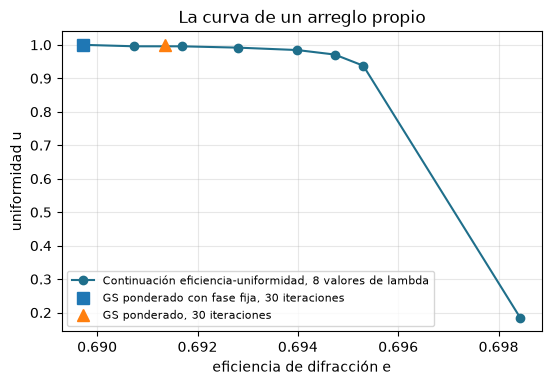

In [19]:
# la curva del arreglo propio, con los dos hologramas de un punto
fig, ax = plt.subplots(figsize=(6.2, 3.9))
ax.plot(mine_front[:, 0], mine_front[:, 1], "o-", color="#1f6f8b",
    label="Continuación eficiencia-uniformidad, 8 valores de lambda")
for name, mark, label in (("GS ponderado con fase fija", "s", "GS ponderado con fase fija, 30 iteraciones"),
    ("GS ponderado", "^", "GS ponderado, 30 iteraciones")):
    h = singles[name].history[-1]
    ax.plot(h["efficiency"], h["uniformity"], mark, markersize=8, label=label)
ax.set_xlabel("eficiencia de difracción e")
ax.set_ylabel("uniformidad u")
ax.set_title("La curva de un arreglo propio")
ax.legend(fontsize=8)
ax.grid(True, alpha=0.3)
plt.show()

Para este arreglo la curva va de una eficiencia de 0,6897 y una uniformidad de 1,0000 en $\lambda = 0$ a 0,6984 y 0,1843 en $\lambda = 1$, una ganancia de 1,3 por ciento de la luz que cuesta casi toda la uniformidad. El inicio del GS ponderado con fase fija está en 0,6897 y 1,0000, y 1 punto de la curva es al menos tan bueno como él en ambos ejes con una tolerancia de 0,001, que para el inicio de la continuación es su propio extremo de la curva; el GS ponderado está en 0,6914 y 0,9989, con 0 puntos de la curva al menos tan buenos. Estos conteos son la lectura sobre la que actuar: un punto individual sin ningún punto de la curva al menos tan bueno está sobre la curva, uno con varios está bajo él. No dicen que los ocho puntos sean todo la curva; la sección anterior mostró que la densidad de $\lambda$, el presupuesto y el inicio lo mueven. Lo que hay que revisar en tu propia corrida es la primera línea de lo impreso, el extremo uniforme de la curva, que debe ser igual a la eficiencia del inicio, y la caída monótona de la uniformidad a lo largo de $\lambda$; una curva que no es monótono significa que la continuación se perdió y que el presupuesto por valor es muy corto. La figura es para un arreglo y un sorteo de posiciones, y no sostiene una afirmación sobre arreglos de otra densidad.

## Resultados

**Respuesta:** En la tarea de 10 x 10 la continuación traza una curva de 20 puntos, no dominados entre sí, que va de una eficiencia de 0,7930 y una uniformidad de 1,0000 a una eficiencia de 0,8334 y una uniformidad de 0,0074: gana 5,1 por ciento de la luz y pierde toda la uniformidad, de modo que el compromiso es empinado y se paga casi por completo en uniformidad. En la semilla 1 cinco de los seis métodos de punto único quedan bajo ella, cada uno dominado por entre 1 y 9 puntos de la curva (cuatro y seis en las semillas 2 y 3); el GS ponderado con fase fija queda sobre ella, ya que la curva parte del propio holograma del GS ponderado con fase fija (0,7931 frente a 0,7930 con su uniformidad). El hipervolumen de la curva, 0,8198, supera al de los seis puntos, 0,8074, y al de los cuatro del criterio, 0,8028. La afirmación no sobrevive sin cambios a una línea base más fuerte: el GS ponderado con 100 iteraciones, en 0,8075 y 0,9887, domina 4 de los 20 puntos de la curva. Partiendo de ese holograma, la continuación da una curva cuyo extremo uniforme está en 0,8075 y 1,0000, con un hipervolumen de 0,8216; las dos curvas se intercalan y su unión llega a 0,8220. El área que la curva agrega a los cinco puntos publicados depende de la referencia del hipervolumen: +0,0124 desde el origen y +0,0008 con el piso de uniformidad (0; 0,9), porque la ganancia de la curva está del lado eficiente, donde la uniformidad es muy inferior a uno.

Lo que el notebook no establece es el frente de Pareto de la tarea: la curva queda bajo él donde un iterado publicado domina uno de sus puntos, y el benchmark del producto, que guarda una curva por geometría, no le da ninguna victoria con su regla de cinco semillas de cada lado (este notebook no vuelve a ejecutar el benchmark). El conteo de dominancia se repitió con tres semillas y dio cinco, cuatro y seis de los seis puntos únicos bajo la curva, de modo que el conteo pertenece a la semilla, mientras que el criterio del hipervolumen se cumplió en las tres; el rango de eficiencia de la curva es lo bastante pequeño como para que otro haz u otro número de trampas cambie su forma.

## Resumen

- Un holograma es un punto en el plano de eficiencia y uniformidad, y un método con un parámetro libre es una curva; el frente de Pareto es el conjunto que nada domina, y la curva de un método es un frente solo si ningún punto alcanzable por otro método la domina.
- El método de continuación eficiencia-uniformidad la traza por continuación sobre una sola pérdida, con $\lambda$ moviéndose de trampas iguales a solo luz, con inicio caliente a lo largo del camino.
- En esta tarea la curva es empinada: 5,1 por ciento más de luz cuesta toda la uniformidad.
- Con el presupuesto del benchmark cinco de seis métodos de punto único quedan bajo la curva en la semilla 1 (cuatro y seis en las semillas 2 y 3), con márgenes de cerca de 0,003 a 0,1348 de la luz con igual uniformidad; el GS ponderado con fase fija, su inicio, queda sobre ella.
- El área que la curva agrega a los cinco puntos publicados es +0,0124 desde el origen y solo +0,0008 con el piso de uniformidad (0; 0,9): la ganancia está donde la uniformidad es muy inferior a uno.
- La curva depende de su inicio, de su presupuesto y de su número de $\lambda$: el GS ponderado a 100 iteraciones domina 4 de sus 20 puntos, y una curva que parte de ese holograma es más alta en ambos extremos pero se intercala con la primera.

## Referencias

- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Polin et al. (2005). Optimized holographic optical traps. Optics Express 13, 5831. https://doi.org/10.1364/OPEX.13.005831
- Kim et al. (2019). Large-scale uniform optical focus array generation with a phase spatial light modulator. Optics Letters 44, 3178. https://doi.org/10.1364/OL.44.003178
- Boyd and Vandenberghe (2004). Convex Optimization, chapter 4,7 on multicriterion optimization and Pareto optimality. Cambridge University Press. https://web.stanford.edu/~boyd/cvxbook/
